# Предобработка данных и выделение признаков

Предобработка готовит входное представление для модели. Даже корректно прочитанная и проверенная таблица может содержать даты, текстовые категории и допустимые пропуски. **Выделение признаков** превращает доступное описание объекта в полезные входные поля, а **выбор признаков** определяет, какие из этих полей передавать дальше.

В примере нужно подготовить описание обращения к сервису до решения о ручной проверке. Учебные обращения отделены от новых. Для новых встречаются неизвестный канал, неизвестный уровень приоритета, пропуски и количество вложений больше учебных значений.

Все данные создаются внутри ноутбука, скачивание файлов и моделей не требуется. Примеры выполнены, результаты и рисунки сохранены. Перед каждым кодовым блоком описана его цель, после результата разобраны использованные конструкции Python и параметры. Материал рассчитан на последовательное изучение с нуля, без заданий и математической теории.

Для повторного выполнения нужны NumPy, Pandas, Matplotlib и scikit-learn. Ячейки запускаются сверху вниз в одном ядре. Загрузка и проверка исходных файлов были разобраны ранее; здесь используются уже подготовленные значения.

**Содержание**

- [1. Какие поля доступны модели](#inputs)
- [2. Выделение признаков из исходных полей](#features)
- [3. Числовые поля: пропуски и масштаб](#numbers)
- [4. Категории: состав и порядок](#categories)
- [5. Единый процесс преобразования](#workflow)
- [6. Проверка и чтение результата](#inspection)

<a id="inputs"></a>
## 1. Какие поля доступны модели

### 1.1. Признак должен существовать в момент применения

Одно наблюдение — одно обращение. До решения доступны время создания, канал, заявленный приоритет, количество вложений и сообщение. Известное решение специалиста — **целевой ответ**, который хранится отдельно от входов.

Фактическое время ожидания появляется после обработки. Использование такого поля при предсказании заранее передало бы сведения из будущего. Это один из вариантов **утечки данных**: подготовка получает информацию, недоступную при настоящем применении.

Идентификатор помогает связывать строки, но в этом примере не описывает содержание обращения. Он становится индексом таблицы. Метаданные об источнике будут отдельно проверены на полезность для различения объектов.

Первый блок подключает средства для таблиц, рисунков и преобразований. Отдельные компоненты будут сначала показаны по шагам, затем соединены в общий процесс. Настройки рисунков обеспечивают русские подписи и автоматическое размещение элементов.

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.constrained_layout.use'] = True
print('Компоненты предобработки подключены.')

Компоненты предобработки подключены.


**Разбор кода.**

- `%matplotlib inline` — команда Jupyter, включающая показ рисунков внутри ноутбука. Остальные строки — обычные инструкции Python.
- `import` подключает установленную библиотеку. `as np`, `as pd`, `as plt` дают короткие имена. Точка в `matplotlib.pyplot` выбирает часть библиотеки для рисования.
- `from ... import ...` подключает отдельные имена. Запятые позволяют перечислить несколько имён из одного модуля. `display` показывает таблицы, NumPy понадобится также для явного пропуска `np.nan`.
- `SimpleImputer` заполняет пропуски, `MissingIndicator` создаёт признаки их наличия. `MinMaxScaler` меняет масштаб числовых полей. `OneHotEncoder` и `OrdinalEncoder` представляют категории числовыми столбцами.
- `ColumnTransformer` назначает разные обработки разным группам полей. `Pipeline` соединяет последовательные шаги. `FunctionTransformer` включает нашу функцию выделения признаков в такой процесс. Функция `clone` создаёт новый компонент с теми же настройками, без переноса обученного состояния.
- Текст в кавычках — строковое значение. `plt.rcParams[...]` выбирает настройку по ключу. Один знак `=` присваивает значение. `True` означает логическое «включено».
- `print(...)` — вызов функции вывода. Круглые скобки означают вызов, строка внутри — аргумент. Подключение классов ещё не создаёт конкретные обученные преобразователи.

Каждый компонент ниже получит своё имя переменной, настройки и данные. Наличие общего метода `fit` у преобразователя не делает его классификатором: здесь этот метод настраивает подготовку входов.

Следующий блок создаёт восемь учебных обращений с известным решением и фактическим временем ожидания. Пропуски вложений и сообщения оставлены намеренно как допустимое отсутствие сведений. Даты сразу переводятся в тип даты и времени, а идентификатор назначается индексом.

In [2]:
training_rows = [
    ('R001', '2026-10-01 09:10', 'web', 'обычный', 0, 'Как войти в кабинет?', 'нет', 2.0),
    ('R002', '2026-10-01 18:30', 'email', 'срочный', 2, 'Ошибка загрузки файла', 'да', 12.0),
    ('R003', '2026-10-03 11:20', 'mobile', 'низкий', 1, 'Спасибо за ответ', 'нет', 1.0),
    ('R004', '2026-10-04 15:00', 'web', 'обычный', np.nan, 'Не открывается раздел', 'да', 8.0),
    ('R005', '2026-10-05 10:15', 'email', 'срочный', 3, None, 'да', 9.0),
    ('R006', '2026-10-05 13:40', np.nan, 'низкий', 1, 'Нужна копия документа', 'нет', 4.0),
    ('R007', '2026-10-06 08:25', 'web', 'обычный', 0, 'Ошибка в подписи', 'да', 6.0),
    ('R008', '2026-10-06 19:10', 'mobile', 'обычный', 2, 'Где находится настройка?', 'нет', 3.0),
]
training_requests = pd.DataFrame(training_rows, columns=[
    'request_id', 'created_at', 'channel', 'priority', 'attachment_count',
    'message', 'needs_review', 'actual_wait_minutes',
]).set_index('request_id')
training_requests['created_at'] = pd.to_datetime(
    training_requests['created_at'], format='%Y-%m-%d %H:%M',
)
training_requests['source_system'] = 'service_v1'
display(training_requests[['created_at', 'channel', 'priority', 'attachment_count', 'needs_review']])

,created_at,channel,priority,attachment_count,needs_review
request_id,,,,,
R001,2026-10-01 09:10:00,web,обычный,0.0,нет
R002,2026-10-01 18:30:00,email,срочный,2.0,да
R003,2026-10-03 11:20:00,mobile,низкий,1.0,нет
R004,2026-10-04 15:00:00,web,обычный,NaN,да
R005,2026-10-05 10:15:00,email,срочный,3.0,да
R006,2026-10-05 13:40:00,NaN,низкий,1.0,нет
R007,2026-10-06 08:25:00,web,обычный,0.0,да
R008,2026-10-06 19:10:00,mobile,обычный,2.0,нет


**Разбор кода.**

- `training_rows = [...]` создаёт список записей. Каждый внутренний кортеж `(...)` содержит поля одного обращения в одинаковом порядке. Запятые разделяют значения и записи.
- Текст в кавычках хранится как строка. `0`, `2`, `3` — целые количества, `2.0` — дробная запись. `np.nan` обозначает отсутствующее числовое значение, `None` — отсутствие объекта Python; в текстовом поле Pandas тоже распознаёт его как пропуск.
- `pd.DataFrame(..., columns=[...])` создаёт таблицу, сопоставляя позиции в кортежах именам столбцов. `.set_index('request_id')` делает идентификаторы подписями строк и убирает их из обычных столбцов.
- `pd.to_datetime(...)` переводит уже проверенные текстовые даты в специальный тип. В формате `%Y-%m-%d %H:%M` указаны год, месяц, день, час и минута. Символы `%` внутри строки описывают формат, а не команду Jupyter.
- `training_requests['created_at'] = ...` записывает преобразованный результат в поле. Новое присваивание `['source_system'] = 'service_v1'` добавляет один и тот же текст источника во все строки.
- `needs_review` — известное решение, `actual_wait_minutes` — результат последующего процесса. Они присутствуют в истории, но не должны автоматически оказаться входами модели.
- `display(...)` показывает выбранный список полей. Двойные квадратные скобки сохраняют табличный вид. Остальные поля остаются в `training_requests`, даже если не выведены.

Нулевое количество вложений и неизвестное количество имеют разный смысл. Дальше эта разница будет сохранена отдельным признаком отсутствия.

Этот блок фиксирует список доступных входных полей и отдельно сохраняет целевой ответ. В выводе показаны имена входов и первые ответы. Фактическое ожидание и идентификатор среди входных столбцов отсутствуют.

In [3]:
source_columns = [
    'created_at', 'channel', 'priority', 'attachment_count', 'message', 'source_system',
]
training_inputs = training_requests.loc[:, source_columns].copy()
training_targets = training_requests['needs_review'].copy()

print('Исходные входы:', training_inputs.columns.tolist())
display(training_targets.head(4))

Исходные входы: ['created_at', 'channel', 'priority', 'attachment_count', 'message', 'source_system']


request_id
R001    нет
R002     да
R003    нет
R004     да
Name: needs_review, dtype: object

**Разбор кода.**

- `source_columns = [...]` сохраняет список разрешённых имён. Одного хранения таблицы недостаточно: именно список задаёт входной состав этого примера.
- `.loc[:, source_columns]` выбирает все строки через `:` и указанные столбцы через список после запятой. `.copy()` создаёт отдельную рабочую таблицу.
- `training_requests['needs_review']` выбирает целевой столбец как Series. Его `.copy()` сохраняется в отдельной переменной `training_targets`; он не добавляется к входам преобразователей.
- `.columns.tolist()` сначала получает имена столбцов, затем превращает их в список Python. `print(...)` выводит этот список с подписью.
- `.head(4)` возвращает первые четыре ответа для `display(...)`. Индекс с идентификаторами сохраняет соответствие описаний и ответов.

Цель дальнейших ячеек — получить представление входов. Обучение модели решения по этим признакам здесь не запускается, поэтому наличие готовой таблицы ещё не говорит о качестве предсказаний.

### 1.2. Учебные данные и новые входы

У преобразователей могут быть запоминаемые настройки: границы числовых полей, список встреченных категорий, порядок выходных столбцов. Они определяются на учебных данных. К новым входам применяется уже сохранённое преобразование.

Это вторая граница защиты от утечки: новые данные не должны незаметно перенастраивать подготовку модели. Неизвестная категория и отсутствующее значение требуют заранее выбранного поведения.

Следующий блок создаёт три новых обращения без готового решения и времени ожидания. Канал chat и приоритет «экстренный» не встречались в учебной таблице; количество 12 выходит за её наблюдавшиеся количества. Эти случаи помогут проверить поведение преобразований при применении.

In [4]:
new_rows = [
    ('N001', '2026-10-07 10:20', 'chat', 'срочный', 12, 'Ошибка выгрузки нескольких документов'),
    ('N002', '2026-10-10 20:40', 'web', 'экстренный', np.nan, None),
    ('N003', '2026-10-11 08:00', np.nan, 'обычный', 1, 'Нужно проверить изображение'),
]
new_requests = pd.DataFrame(new_rows, columns=[
    'request_id', 'created_at', 'channel', 'priority', 'attachment_count', 'message',
]).set_index('request_id')
new_requests['created_at'] = pd.to_datetime(new_requests['created_at'], format='%Y-%m-%d %H:%M')
new_requests['source_system'] = 'service_v1'
new_inputs = new_requests.loc[:, source_columns].copy()
display(new_inputs)

,created_at,channel,priority,attachment_count,message,source_system
request_id,,,,,,
N001,2026-10-07 10:20:00,chat,срочный,12.0,Ошибка выгрузки нескольких документов,service_v1
N002,2026-10-10 20:40:00,web,экстренный,NaN,None,service_v1
N003,2026-10-11 08:00:00,NaN,обычный,1.0,Нужно проверить изображение,service_v1


**Разбор кода.**

- `new_rows` — список кортежей, каждый задаёт одно новое обращение. `np.nan` и `None` сохраняют отсутствие сведений; строковые новые категории переданы буквально, без предварительной подмены известными.
- `pd.DataFrame(..., columns=[...])` создаёт таблицу шести полей. `.set_index(...)` переносит идентификатор в индекс, сохраняя его для связи результата с объектом.
- `pd.to_datetime(..., format=...)` применяет тот же заданный формат даты. Это детерминированное преобразование каждого значения, которому не нужно изучать новую таблицу для выбора правил.
- Присваивание `['source_system'] = ...` добавляет метаданные. `.loc[:, source_columns].copy()` выбирает такой же состав исходных входов и в таком же порядке, что был задан для учебных данных.
- `display(new_inputs)` показывает все новые строки. Целевого поля и фактического ожидания здесь нет, и никакой код не заполняет их предположениями.

Новые объекты готовы для применения будущего процесса, но ещё не для произвольного повторного `fit` по ним. Знание новой категории само по себе не должно менять входной размер уже подготовленной модели.

### 1.3. Выбор полей и константный столбец

Поле, одинаковое у всех учебных объектов, не различает эти объекты. В нашей таблице таковы метаданные источника. Решение о его исключении принимается по учебной таблице и затем одинаково применяется к новым входам.

Это простой пример **выбора признаков**. Он отличается от извлечения новых характеристик из текста или даты. Отсутствие различий сейчас не доказывает, что поле никогда не станет полезным в другой задаче или новом источнике.

Этот блок считает число различных значений каждого входного поля на учебных строках. Поля с единственным значением исключаются из обеих таблиц по одному сохранённому списку. Новая таблица не используется для повторного определения этого списка.

In [5]:
distinct_counts = training_inputs.nunique(dropna=False)
constant_columns = distinct_counts.index[distinct_counts.eq(1)].tolist()
selected_training = training_inputs.drop(columns=constant_columns)
selected_new = new_inputs.drop(columns=constant_columns)

display(distinct_counts.rename('Различных значений в учебных данных'))
print('Исключены константные поля:', constant_columns)

created_at          8
channel             4
priority            3
attachment_count    5
message             8
source_system       1
Name: Различных значений в учебных данных, dtype: int64

Исключены константные поля: ['source_system']


**Разбор кода.**

- `.nunique(dropna=False)` возвращает число различных значений в каждом столбце. `dropna=False` учитывает пропуск как отдельный вариант, чтобы заполненность только частью объектов не выглядела константой.
- `.eq(1)` создаёт логическую маску полей с единственным вариантом. `distinct_counts.index[маска]` выбирает соответствующие имена. `.tolist()` сохраняет их обычным списком `constant_columns`.
- `.drop(columns=constant_columns)` возвращает таблицу без указанных столбцов. Передаётся один и тот же список для учебных и новых входов, поэтому их состав согласован.
- Новые объекты сохраняются в `selected_training`, `selected_new`. Исходные `training_inputs`, `new_inputs` этим присваиванием не изменяются.
- `.rename(...)` задаёт имя Series для просмотра, `display(...)` показывает счётчики. `print(...)` выводит конкретные исключённые имена.

В данном наборе исключён `source_system`. Идентификатор и будущий результат были отделены раньше по смыслу, а не по этому правилу количества вариантов.

<a id="features"></a>
## 2. Выделение признаков из исходных полей

Из даты можно получить календарный признак, из сообщения — длину и наличие выбранной подстроки. Такие действия применяются к каждому объекту по заранее заданному правилу и не требуют целевых ответов.

Созданные поля описывают только конкретные свойства. Длина не представляет весь смысл сообщения, а наличие подстроки «ошибка» не является подтверждённым решением о ручной проверке. Пустое сообщение также не следует объявлять сообщением без каких-либо проблем.

Следующий блок определяет функцию выделения трёх полей: длины сообщения, наличия подстроки «ошибка» и выходного дня. Она одинаково применяется к учебным и новым объектам. Для отсутствующего сообщения длина остаётся неизвестной; отдельный признак пропуска будет добавлен позже.

In [6]:
def extract_features(table):
    result = table.copy()
    result['message_length'] = result['message'].str.len()
    result['mentions_error'] = result['message'].str.contains(
        'ошибка', case=False, regex=False, na=False,
    ).astype('int64')
    result['is_weekend'] = result['created_at'].dt.dayofweek.ge(5).astype('int64')
    return result

training_features = extract_features(selected_training)
new_features = extract_features(selected_new)
display(training_features[[
    'attachment_count', 'message_length', 'mentions_error', 'is_weekend',
]])

,attachment_count,message_length,mentions_error,is_weekend
request_id,,,,
R001,0.0,20.0,0,0
R002,2.0,21.0,1,0
R003,1.0,16.0,0,1
R004,NaN,21.0,0,1
R005,3.0,NaN,0,0
R006,1.0,21.0,0,0
R007,0.0,16.0,1,0
R008,2.0,24.0,0,0


**Разбор кода.**

- `def extract_features(table):` определяет функцию одного параметра. Строки с отступом — её тело. `.copy()` создаёт результат отдельно от переданной таблицы; `return result` возвращает готовую таблицу вызывающему коду.
- `result['message'].str.len()` вычисляет длину каждого текстового значения. `.str` включает поэлементные строковые операции, `.len()` считает символы, включая пробелы. Это длина текста, а не число слов или токенов.
- `.str.contains('ошибка', ...)` проверяет наличие указанной подстроки. `case=False` игнорирует регистр, `regex=False` ищет буквальный текст, `na=False` возвращает ложь при пропуске сообщения.
- `.astype('int64')` превращает логические результаты в целые коды: 1 — свойство обнаружено, 0 — не обнаружено. Для пропущенного текста 0 сам по себе не доказывает отсутствие смысла; далее сохранится признак отсутствия сведений.
- `.dt` открывает календарные свойства Series с датами. `.dayofweek` возвращает номер дня недели: понедельник 0, воскресенье 6. `.ge(5)` проверяет субботу и воскресенье, затем результат тоже переводится в целый флаг.
- Присваивания новых `result['...']` добавляют поля, не убирая пока исходные дату и сообщение. Выбор окончательных столбцов будет задан отдельно.
- Два вызова `extract_features(...)` используют одну функцию для разных таблиц. `display(...)` показывает четыре поля учебного результата; двойные квадратные скобки выбирают список столбцов.

Индекс обращений сохраняется. В функции нет чтения `needs_review`, фактического ожидания или других объектов, поэтому её правила не извлекают недоступные сведения из соседних строк.

<a id="numbers"></a>
## 3. Числовые поля: пропуски и масштаб

### 3.1. Заполнитель и факт отсутствия

Для выбранного числового представления пропуск заменяется техническим значением 0. Оно не означает восстановленное измерение. Чтобы отличить подстановку от настоящего нуля, отдельный компонент сохранит признаки отсутствия исходных значений.

**`fit`** настраивает преобразователь по учебным данным, **`transform`** применяет сохранённые правила, **`fit_transform`** выполняет оба действия последовательно. При обработке новых входов здесь используется только `transform`.

Следующий блок выбирает два числовых поля и создаёт заполнитель пропусков. Он настраивается на учебных строках и затем применяется к новым. Числовой результат показывается как таблица с сохранёнными именами полей и индексом обращений.

In [7]:
numeric_columns = ['attachment_count', 'message_length']
training_numbers = training_features.loc[:, numeric_columns]
new_numbers = new_features.loc[:, numeric_columns]

number_filler = SimpleImputer(
    strategy='constant', fill_value=0, keep_empty_features=True,
).set_output(transform='pandas')
filled_training_numbers = number_filler.fit_transform(training_numbers)
filled_new_numbers = number_filler.transform(new_numbers)
display(filled_training_numbers)

,attachment_count,message_length
request_id,,
R001,0.0,20.0
R002,2.0,21.0
R003,1.0,16.0
R004,0.0,21.0
R005,3.0,0.0
R006,1.0,21.0
R007,0.0,16.0
R008,2.0,24.0


**Разбор кода.**

- `numeric_columns = [...]` задаёт список двух имён. `.loc[:, numeric_columns]` выбирает все строки и эти поля. Текстовое имя `message_length` относится к ранее извлечённой длине.
- `SimpleImputer(...)` создаёт компонент заполнения. `strategy='constant'` выбирает постоянный заполнитель, `fill_value=0` задаёт его значение. Слева внутри вызова стоят имена параметров, справа — их значения.
- `keep_empty_features=True` сохраняет столбец даже при полном отсутствии наблюдаемых значений в учебных строках. Это настройка сохранения состава полей, а не доказательство наличия данных.
- `.set_output(transform='pandas')` просит возвращать DataFrame, чтобы сохранить имена и индекс для просмотра. Она настраивает формат результата и сама не выполняет преобразование данных.
- `.fit_transform(training_numbers)` настраивает компонент и возвращает преобразованные учебные строки. `.transform(new_numbers)` использует уже настроенный объект для новых строк.
- Оба результата присваиваются разным именам. `display(...)` показывает учебный результат. Отсутствие повторного `fit` у новых строк делает режим применения явным.

Теперь числовых пропусков нет, но R004 с неизвестным числом вложений и R001 с реальным нулём получили одинаковое число в этом поле. Следующий признак восстановит различимость этих ситуаций.

Этот блок создаёт признаки отсутствия для обоих числовых полей на основе их значений до заполнения. Он использует одинаковый состав признаков для учебных и новых объектов, даже если рисунок пропусков у них отличается.

In [8]:
missing_indicator = MissingIndicator(features='all').set_output(transform='pandas')
training_missing_flags = missing_indicator.fit_transform(training_numbers)
new_missing_flags = missing_indicator.transform(new_numbers)

display(training_missing_flags)
display(new_missing_flags)

,missingindicator_attachment_count,missingindicator_message_length
request_id,,
R001,False,False
R002,False,False
R003,False,False
R004,True,False
R005,False,True
R006,False,False
R007,False,False
R008,False,False


,missingindicator_attachment_count,missingindicator_message_length
request_id,,
N001,False,False
N002,True,True
N003,False,False


**Разбор кода.**

- `MissingIndicator(...)` создаёт преобразователь, который отвечает, отсутствовало ли значение. `features='all'` требует отдельный признак для каждого переданного поля.
- Такая настройка фиксирует состав флагов. Признак останется и для поля, у которого учебные значения могли бы быть полностью заполнены, а новое значение оказалось отсутствующим.
- `.set_output(transform='pandas')` сохраняет оформленную таблицу. `.fit_transform(training_numbers)` использует исходные числовые поля, **не** результат заполнения нулями: иначе сведения о пропусках уже были бы потеряны.
- `.transform(new_numbers)` применяет тот же компонент. Значение `True` означает исходное отсутствие, `False` — наличие значения. Имена выходных полей создаёт компонент.
- Два вызова `display(...)` показывают обе таблицы. Индексы сохраняют, к каким обращениям относится каждый флаг.

У N002 отсутствуют и число вложений, и сообщение. Флаг длины отражает отсутствие исходного текста, которое нельзя узнать только по уже заполненной нулевой длине.

### 3.2. Изменение масштаба числовых полей

Количество вложений и длина сообщения имеют разные диапазоны. Для некоторых моделей важно подготовить сопоставимый числовой масштаб. Требования конкретной модели различаются; само изменение масштаба не создаёт нового содержания поля.

В примере используется `MinMaxScaler`: по учебным значениям он запоминает границы. У непостоянного учебного поля нижняя граница получает 0, верхняя — 1, остальные значения располагаются между ними. Запомненные правила затем используются при применении. Настройка выполняется после выбранного заполнения пропусков.

Следующий блок настраивает изменение масштаба на заполненных учебных числах. Он показывает запомненные границы по каждому полю и полученные учебные значения. Имена полей и идентификаторы обращений сохраняются.

In [9]:
number_scaler = MinMaxScaler(clip=False).set_output(transform='pandas')
scaled_training_numbers = number_scaler.fit_transform(filled_training_numbers)
learned_limits = pd.DataFrame({
    'Нижняя учебная граница': number_scaler.data_min_,
    'Верхняя учебная граница': number_scaler.data_max_,
}, index=numeric_columns)

display(learned_limits)
display(scaled_training_numbers.round(3))

,Нижняя учебная граница,Верхняя учебная граница
attachment_count,0.0,3.0
message_length,0.0,24.0


,attachment_count,message_length
request_id,,
R001,0.000,0.833
R002,0.667,0.875
R003,0.333,0.667
R004,0.000,0.875
R005,1.000,0.000
R006,0.333,0.875
R007,0.000,0.667
R008,0.667,1.000


**Разбор кода.**

- `MinMaxScaler(clip=False)` создаёт компонент масштаба. Параметр `clip=False` сохраняет возможность выхода новых значений за учебный диапазон, вместо обрезания результата по его краям.
- `.set_output(...)` задаёт табличный формат, `.fit_transform(...)` изучает границы переданных учебных полей и возвращает преобразованные строки. Передаются уже заполненные числа, поэтому технические нули участвуют в настройке.
- `.data_min_`, `.data_max_` — атрибуты с запомненными границами. Конечное подчёркивание является частью имён и указывает на сведения, полученные при настройке. Атрибуты читаются без круглых скобок.
- `pd.DataFrame({...}, index=numeric_columns)` собирает границы в понятную таблицу. Словарь задаёт названия её столбцов, аргумент `index` — подписи строк с исходными полями.
- `display(...)` показывает таблицы. `.round(3)` возвращает округлённые значения для вывода с тремя знаками после точки; сам объект масштаба этой операцией не меняется.

Новые координаты — подготовленное представление, а не исходное количество вложений или длина в символах. Для объяснения исходных величин сохраняются отдельные таблицы до преобразования.

Этот блок применяет сохранённый масштаб к заполненным новым значениям. Вначале выводятся исходные подготовленные числа, затем их представление после преобразования. В конце ещё раз показаны учебные верхние границы: новые обращения их не перенастраивали.

In [10]:
scaled_new_numbers = number_scaler.transform(filled_new_numbers)
display(filled_new_numbers)
display(scaled_new_numbers.round(3))
print('Сохранённые верхние границы:', number_scaler.data_max_)

,attachment_count,message_length
request_id,,
N001,12.0,37.0
N002,0.0,0.0
N003,1.0,27.0


,attachment_count,message_length
request_id,,
N001,4.000,1.542
N002,0.000,0.000
N003,0.333,1.125


Сохранённые верхние границы: [ 3. 24.]


**Разбор кода.**

- `number_scaler.transform(...)` вызывает режим применения уже настроенного компонента. Он не получает команду снова изучать границы новой таблицы.
- В `filled_new_numbers` N001 содержит 12 вложений. Учебная верхняя граница этого поля была 3, поэтому после применения сохранённого масштаба результат оказывается выше 1.
- При `clip=False` это ожидаемое поведение, а не ошибка функции. Выход за учебный диапазон показывает, что новые значения отличаются от использованных при настройке. Он сам по себе не определяет ошибочность исходного обращения.
- `.round(3)` оформляет только показ результата, `display(...)` выводит две таблицы. `print(...)` читает сохранённый атрибут `.data_max_` для сопоставления с предыдущим блоком.

Заново подстроить границы по новым обращениям означало бы поменять смысл входных чисел относительно учебного набора. Поэтому на этом этапе используется `transform`, а не `fit_transform`.

<a id="categories"></a>
## 4. Категории: состав и порядок

### 4.1. Номинальная категория и отсутствующее значение

Канал web, email или mobile задаёт название категории. Для этой задачи у каналов нет естественного порядка. **One-hot-кодирование** создаёт отдельный столбец для каждого известного варианта: выбранному варианту соответствует 1, остальным 0.

Пропуск канала и новый канал chat — разные ситуации. В примере пропуск получает отдельную текстовую категорию «не указан». Для неизвестного нового названия отдельно задаётся поведение кодировщика.

Следующий блок заполняет только отсутствующий канал, сохраняя реальные названия. Компонент настраивается на учебных данных и применяется к новым. Неизвестный канал chat остаётся своим текстом: он не является пропуском.

In [11]:
nominal_columns = ['channel']
channel_filler = SimpleImputer(
    strategy='constant', fill_value='не указан', keep_empty_features=True,
).set_output(transform='pandas')
filled_training_channels = channel_filler.fit_transform(training_features.loc[:, nominal_columns])
filled_new_channels = channel_filler.transform(new_features.loc[:, nominal_columns])

display(filled_training_channels.drop_duplicates())
display(filled_new_channels)

,channel
request_id,
R001,web
R002,email
R003,mobile
R006,не указан


,channel
request_id,
N001,chat
N002,web
N003,не указан


**Разбор кода.**

- `nominal_columns` — список имён полей с категориями без заданного порядка. Здесь выбран один столбец.
- `SimpleImputer(strategy='constant', fill_value='не указан', ...)` использует строковый заполнитель. В отличие от числового компонента, справа передан текст в кавычках.
- `keep_empty_features=True` сохраняет поле, даже если его учебные значения полностью отсутствовали бы. `.set_output(transform='pandas')` возвращает таблицу.
- `.fit_transform(...)` настраивает объект по учебной таблице, `.transform(...)` применяет его к новой. `.loc[:, nominal_columns]` выбирает одинаковые поля в обоих случаях.
- `.drop_duplicates()` оставляет разные получившиеся названия для компактного просмотра, а `display(...)` показывает их и новые строки. Весь `filled_training_channels` этим показом не сокращается.

Учебный пропуск стал категорией «не указан». Значение chat не было заменено, поскольку оно присутствовало в исходном поле и требует обработки как неизвестная категория.

Этот блок настраивает one-hot-кодировщик на заполненных учебных каналах. Он показывает получившиеся столбцы и запомненный список категорий. Число столбцов определяется учебными вариантами и сохраняется при дальнейшем применении.

In [12]:
channel_encoder = OneHotEncoder(
    handle_unknown='ignore', sparse_output=False,
).set_output(transform='pandas')
encoded_training_channels = channel_encoder.fit_transform(filled_training_channels)

display(encoded_training_channels)
print('Изученные категории:', channel_encoder.categories_)

,channel_email,channel_mobile,channel_web,channel_не указан
request_id,,,,
R001,0.0,0.0,1.0,0.0
R002,1.0,0.0,0.0,0.0
R003,0.0,1.0,0.0,0.0
R004,0.0,0.0,1.0,0.0
R005,1.0,0.0,0.0,0.0
R006,0.0,0.0,0.0,1.0
R007,0.0,0.0,1.0,0.0
R008,0.0,1.0,0.0,0.0


Изученные категории: [array(['email', 'mobile', 'web', 'не указан'], dtype=object)]


**Разбор кода.**

- `OneHotEncoder(...)` создаёт кодировщик. `handle_unknown='ignore'` задаёт поведение для отсутствовавшего при настройке названия: известные столбцы этой группы получат нули.
- `sparse_output=False` выбирает обычную плотную таблицу для небольшого учебного набора. Вариант по умолчанию использует разреженное хранение; для выбранного здесь табличного показа нужно явно отключить его.
- `.set_output(transform='pandas')` возвращает DataFrame с созданными именами. `.fit_transform(filled_training_channels)` запоминает категории учебного поля и кодирует эти же строки.
- `.categories_` — атрибут со списками известных категорий для входных полей. Он читается после настройки и не требует скобок. Названия выходных столбцов соединяют имя поля и категорию.
- `display(...)` показывает коды, `print(...)` — содержимое атрибута. Значения 0.0 и 1.0 являются числовым представлением признаков принадлежности, а не вероятностями или степенью качества канала.

Четыре учебных варианта включают три названных канала и отдельное отсутствие. Новый столбец для chat на этапе применения автоматически добавляться не будет.

Следующий блок кодирует новые каналы тем же объектом и сопоставляет исходный текст, заполненный текст и готовые признаки. В одной таблице видны все три случая: неизвестное название, известный канал и отсутствие значения.

In [13]:
encoded_new_channels = channel_encoder.transform(filled_new_channels)
channel_view = pd.concat([
    new_features[['channel']].rename(columns={'channel': 'Исходный канал'}),
    filled_new_channels.rename(columns={'channel': 'После заполнения'}),
    encoded_new_channels,
], axis=1)
display(channel_view)

,Исходный канал,После заполнения,channel_email,channel_mobile,channel_web,channel_не указан
request_id,,,,,,
N001,chat,chat,0.0,0.0,0.0,0.0
N002,web,web,0.0,0.0,1.0,0.0
N003,NaN,не указан,0.0,0.0,0.0,1.0


**Разбор кода.**

- `.transform(...)` использует ранее изученные категории без нового `fit`. Форма и порядок числовых столбцов остаются учебными.
- `new_features[['channel']]` выбирает один столбец как таблицу. `.rename(columns={...})` переименовывает его только для понятного просмотра; словарь задаёт старое и новое имя.
- `pd.concat([...], axis=1)` соединяет список таблиц рядом по столбцам. Их строки совмещаются по индексам обращений, которые сохранились у всех трёх частей.
- `display(channel_view)` показывает составной результат. Для chat все четыре известных индикатора равны нулю. Для web активен его столбец; для отсутствия активен столбец категории «не указан».

Все нули группы здесь имеют конкретный смысл настройки `ignore`: входное название неизвестно кодировщику. Это не то же представление, что заполненный пропуск. Требования к дальнейшей обработке неизвестных категорий задаются отдельно для прикладной задачи.

### 4.2. Категория с заданным порядком

В приоритете есть заранее определённый порядок: низкий, обычный, срочный. **Порядковое кодирование** сохраняет его через коды 0, 1, 2. Такой порядок задаётся смыслом поля, а не алфавитом названий.

Неизвестному уровню выделяется служебный код −1. Он не объявляет новый приоритет «ниже низкого» по смыслу. В этом примере приоритет заполнен у всех объектов; обрабатывается именно новое название, а не пропуск.

Этот блок создаёт кодировщик с явным порядком приоритетов и применяет его к двум таблицам. Для новых обращений исходное название показано рядом с кодом. Так можно проверить, что «экстренный» получил служебное значение, а известные уровни сохранили заданный порядок.

In [14]:
priority_columns = ['priority']
priority_order = ['низкий', 'обычный', 'срочный']
priority_encoder = OrdinalEncoder(
    categories=[priority_order],
    handle_unknown='use_encoded_value', unknown_value=-1,
).set_output(transform='pandas')
encoded_training_priority = priority_encoder.fit_transform(training_features.loc[:, priority_columns])
encoded_new_priority = priority_encoder.transform(new_features.loc[:, priority_columns])

priority_view = new_features.loc[:, priority_columns].copy()
priority_view['priority_code'] = encoded_new_priority['priority']
print('Заданный порядок:', priority_order)
display(priority_view)

Заданный порядок: ['низкий', 'обычный', 'срочный']


,priority,priority_code
request_id,,
N001,срочный,2.0
N002,экстренный,-1.0
N003,обычный,1.0


**Разбор кода.**

- `priority_order = [...]` задаёт упорядоченный список названий. `categories=[priority_order]` передаёт список списков: по одному порядку на входной столбец, здесь он один.
- `OrdinalEncoder(...)` создаёт компонент порядкового кодирования. `handle_unknown='use_encoded_value'` разрешает обработку нового названия, `unknown_value=-1` выбирает отдельный код для него.
- `.set_output(...)` сохраняет формат DataFrame. `.fit_transform(...)` настраивает компонент и кодирует учебные строки, `.transform(...)` применяет те же правила к новым.
- `.loc[:, priority_columns].copy()` создаёт таблицу исходных приоритетов для просмотра. Присваивание `['priority_code'] = ...` добавляет числовой результат по совпадающим индексам.
- Коды могут показываться как 1.0 или 2.0, поскольку кодировщик возвращает дробный числовой тип. Смысл категориального кода от такого оформления не меняется.
- `print(...)` выводит заданный порядок, `display(...)` — соответствие новых названий кодам. Отрицательный знак в −1 обозначает выбранный служебный код, а не ошибку выполнения.

Разные способы кодирования выбраны из смысла полей: у канала порядок не задан, у приоритета задан. Произвольно использовать порядковые коды для любых названий было бы другим решением о входном представлении.

<a id="workflow"></a>
## 5. Единый процесс преобразования

### 5.1. Последовательность внутри группы и разные группы полей

В числовой группе сначала заполняются пропуски, затем меняется масштаб. В канале сначала появляется категория отсутствия, затем выполняется one-hot-кодирование. Внутри каждой группы это **последовательность шагов**, которую хранит `Pipeline`.

Разные группы обрабатываются `ColumnTransformer`. Он получает общую таблицу и передаёт каждой ветви выбранные исходные поля. Поэтому ветвь признаков отсутствия видит значения до заполнения в другой ветви. Итоговые столбцы объединяются в одну таблицу.

Два уже извлечённых флага передаются без преобразований. Исходные текст сообщения и дата не входят в окончательный набор: здесь используются выбранные характеристики этих полей.

Следующий блок описывает общий подготовщик из пяти именованных ветвей. Компоненты создаются заново, поэтому самостоятельные демонстрации выше не являются его обученным состоянием. На этом шаге задана только конфигурация, а данные ещё не передавались в её обучение.

In [15]:
flag_columns = ['mentions_error', 'is_weekend']
number_steps = Pipeline([
    ('fill', SimpleImputer(strategy='constant', fill_value=0, keep_empty_features=True)),
    ('scale', MinMaxScaler(clip=False)),
])
channel_steps = Pipeline([
    ('fill', SimpleImputer(strategy='constant', fill_value='не указан', keep_empty_features=True)),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

processor = ColumnTransformer([
    ('numbers', number_steps, numeric_columns),
    ('channels', channel_steps, nominal_columns),
    ('priority', OrdinalEncoder(
        categories=[priority_order], handle_unknown='use_encoded_value', unknown_value=-1,
    ), priority_columns),
    ('missing', MissingIndicator(features='all'), numeric_columns),
    ('flags', 'passthrough', flag_columns),
], remainder='drop', verbose_feature_names_out=True).set_output(transform='pandas')

for name, component, columns in processor.transformers:
    print(name, '→', columns)

numbers → ['attachment_count', 'message_length']
channels → ['channel']
priority → ['priority']
missing → ['attachment_count', 'message_length']
flags → ['mentions_error', 'is_weekend']


**Разбор последовательных шагов.**

- `Pipeline([...])` принимает список кортежей `(имя, компонент)`. Имена `fill`, `scale`, `encode` — выбранные текстовые ключи шагов. Порядок списка задаёт порядок применения.
- `SimpleImputer(...)` в каждой последовательности имеет свой заполнитель. `MinMaxScaler(...)` получает числовой результат заполнения, `OneHotEncoder(...)` — заполненный канал. Их настройки совпадают с разобранными отдельными примерами.
- Создание объектов внутри кортежей не вызывает их `fit`: пока это только настройки. Один знак `=` сохраняет готовую конфигурацию последовательности под именем.

**Разбор ветвей.**

- `ColumnTransformer([...])` принимает кортежи из трёх частей: имя ветви, преобразователь, список исходных столбцов. Например, `('numbers', number_steps, numeric_columns)` направляет числовые поля в последовательность из двух шагов.
- Ветвь `priority` использует свой `OrdinalEncoder` с явно указанным порядком. Ветвь `missing` применяет `MissingIndicator` к тем же двум исходным числовым полям независимо от ветви заполнения.
- Строка `'passthrough'` означает передать выбранные поля без изменения. Здесь это целые флаги, уже созданные нашей функцией. Список `flag_columns` задаёт их порядок.
- `remainder='drop'` исключает остальные поля из результата. Иначе исходные дата и сообщение могли бы остаться рядом с подготовленными характеристиками при другом выборе этой настройки.
- `verbose_feature_names_out=True` добавляет к каждому выходному имени название ветви. Так можно установить, каким действием получен столбец.
- `.set_output(transform='pandas')` настраивает табличный вывод также у вложенных компонентов. Обычный, а не разреженный вывод one-hot задан явно ради этой маленькой таблицы.
- `processor.transformers` хранит список заданных ветвей до обучения. Цикл `for name, component, columns in ...:` распаковывает каждый кортеж в три имени; `print(...)` показывает название и выбранные поля.

Имена ветвей и шагов — часть устройства процесса. Они позволят получить сохранённые настройки конкретного компонента после обучения.

Этот блок настраивает общий подготовщик только по извлечённым учебным признакам. Для компактного чтения готовая таблица показана повёрнутой: названия признаков стоят по строкам, идентификаторы обращений — по столбцам. Фактический рабочий результат сохраняет обычную ориентацию объектов по строкам.

In [16]:
prepared_training = processor.fit_transform(training_features)
display(prepared_training.round(3).T)
print('Учебных объектов:', prepared_training.shape[0])
print('Готовых признаков:', prepared_training.shape[1])

request_id,R001,R002,R003,R004,R005,R006,R007,R008
numbers__attachment_count,0.0,0.667,0.333,0.0,1.0,0.333,0.0,0.667
numbers__message_length,0.833,0.875,0.667,0.875,0.0,0.875,0.667,1.0
channels__channel_email,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
channels__channel_mobile,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
channels__channel_web,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
channels__channel_не указан,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
priority__priority,1.0,2.0,0.0,1.0,2.0,0.0,1.0,1.0
missing__missingindicator_attachment_count,False,False,False,True,False,False,False,False
missing__missingindicator_message_length,False,False,False,False,True,False,False,False
flags__mentions_error,0,1,0,0,0,0,1,0


Учебных объектов: 8
Готовых признаков: 11


**Разбор кода.**

- `processor.fit_transform(training_features)` настраивает все ветви на учебной таблице и объединяет результаты. В вызове нет целевого столбца: эти способы подготовки не используют ответ специалиста.
- Результат `prepared_training` содержит восемь объектов и одиннадцать готовых столбцов. Префиксы `numbers__`, `channels__` и другие указывают ветвь происхождения.
- `.round(3)` создаёт округлённое представление для вывода. `.T` меняет строки и столбцы местами в этом представлении. Атрибут `.T` читается без скобок и не переназначает исходный `prepared_training`.
- `display(...)` показывает повёрнутую таблицу. `shape` — кортеж размеров, `[0]` выбирает число строк, `[1]` — число столбцов. Нумерация начинается с нуля.
- `print(...)` подписывает эти размеры. Новые имена признаков и параметры ветвей уже зафиксированы настройкой по учебным данным.

Один исходный канал превратился в четыре поля, два числовых поля дали также два признака отсутствия. Поэтому количество итоговых полей отличается от количества исходных.

Следующий блок применяет общий подготовщик к новым объектам и проверяет, что не изменились выходные столбцы и сохранённые числовые границы. Новые категории не расширяют схему. Результат снова показан по признакам для удобства чтения трёх обращений.

In [17]:
saved_columns = prepared_training.columns.copy()
learned_scaler = processor.named_transformers_['numbers'].named_steps['scale']
saved_upper_limits = learned_scaler.data_max_.copy()

prepared_new = processor.transform(new_features)
assert prepared_new.columns.equals(saved_columns), 'Изменился состав признаков'
assert np.array_equal(learned_scaler.data_max_, saved_upper_limits), 'Изменились учебные границы'

display(prepared_new.round(3).T)
print('Учебные верхние границы сохранены:', learned_scaler.data_max_)

request_id,N001,N002,N003
numbers__attachment_count,4.0,0.0,0.333
numbers__message_length,1.542,0.0,1.125
channels__channel_email,0.0,0.0,0.0
channels__channel_mobile,0.0,0.0,0.0
channels__channel_web,0.0,1.0,0.0
channels__channel_не указан,0.0,0.0,1.0
priority__priority,2.0,-1.0,1.0
missing__missingindicator_attachment_count,False,True,False
missing__missingindicator_message_length,False,True,False
flags__mentions_error,1,0,0


Учебные верхние границы сохранены: [ 3. 24.]


**Разбор кода.**

- `.columns.copy()` сохраняет отдельную копию выходных имён. `.named_transformers_['numbers']` выбирает обученную числовую ветвь, её `.named_steps['scale']` — шаг масштаба внутри `Pipeline`.
- Конечное подчёркивание в `named_transformers_` указывает на результаты настройки ветвей. `named_steps` содержит именованные шаги последовательности и читается по текстовому ключу.
- `.data_max_.copy()` сохраняет отдельный снимок числовых границ. Простое второе имя для того же массива не было бы независимым снимком.
- `processor.transform(new_features)` применяет подготовщик. Он использует сохранённые настройки и не вызывает повторный `fit` по новой таблице.
- `assert условие, 'сообщение'` останавливает выполнение при ложном условии. `.equals(...)` проверяет совпадение имён и порядка столбцов, `np.array_equal(...)` — точное совпадение двух массивов границ.
- `display(... .round(3).T)` показывает только округлённое повёрнутое представление. `print(...)` читает сохранённые границы у того же компонента после применения.

В N001 число вложений преобразовалось в значение выше 1, неизвестный chat дал нули ветви каналов, а в N002 сохранились признаки отсутствия и служебный код приоритета. Это предусмотренные правила одной неизменной схемы.

### 5.2. Выделение признаков как часть общего процесса

Если выделение признаков отдельно переписать для новых обращений, легко получить отличающееся правило. Нашу функцию можно включить первым шагом общего `Pipeline`, а подготовщик — вторым.

Детерминированная функция получает уже отобранные исходные поля и возвращает таблицу с извлечёнными характеристиками. Настраиваемые ветви затем изучаются только на учебном наборе. Конечный результат процесса — представление входов, а не предсказанное решение.

Этот блок создаёт полный процесс из функции выделения признаков и нового экземпляра подготовщика. Копируются его настройки, но не обученное состояние. Таким образом общий объект можно независимо настроить по исходным учебным входам.

In [18]:
fresh_processor = clone(processor).set_output(transform='pandas')
workflow = Pipeline([
    ('extract', FunctionTransformer(extract_features, validate=False)),
    ('prepare', fresh_processor),
])
print('Шаги полного процесса:', list(workflow.named_steps))

Шаги полного процесса: ['extract', 'prepare']


**Разбор кода.**

- `clone(processor)` создаёт новый объект с такими же настройками, включая вложенные компоненты, но без их обученных границ и категорий. Это поведение отличается от копирования готовых данных через `.copy()`.
- `.set_output(transform='pandas')` явно задаёт табличный результат нового подготовщика. Переменная `fresh_processor` не заменяет ранее изученный `processor`.
- `FunctionTransformer(extract_features, validate=False)` включает нашу функцию в интерфейс преобразователя. Имя функции передано без скобок: запускать её с текущей таблицей будет компонент.
- `validate=False` сохраняет передачу DataFrame с именами, текстом и датами нашей функции, без предварительного преобразования входа в обычный числовой массив.
- `Pipeline([...])` соединяет два шага. Первый добавляет характеристики по единым правилам, второй применяет ветви чисел, категорий и флагов. Имена `extract`, `prepare` используются для обращения к шагам.
- `workflow.named_steps` — отображение имён на компоненты. Встроенный `list(...)` получает список имён в порядке шагов; `print(...)` выводит его.

Здесь созданы новые компоненты, но данные ещё не использовались для их настройки. Отбор доступных исходных полей остаётся явной частью входного договора процесса.

Следующий блок настраивает полный процесс на отобранных исходных учебных полях и применяет его к новым. Проверки сопоставляют результат с уже разобранным пошаговым вариантом. Вход теперь не требует отдельного ручного вызова функции выделения признаков.

In [19]:
workflow_training = workflow.fit_transform(selected_training)
workflow_new = workflow.transform(selected_new)

assert workflow_training.equals(prepared_training), 'Различается учебный результат'
assert workflow_new.equals(prepared_new), 'Различается результат новых объектов'
display(workflow_new.round(3).T)

request_id,N001,N002,N003
numbers__attachment_count,4.0,0.0,0.333
numbers__message_length,1.542,0.0,1.125
channels__channel_email,0.0,0.0,0.0
channels__channel_mobile,0.0,0.0,0.0
channels__channel_web,0.0,1.0,0.0
channels__channel_не указан,0.0,0.0,1.0
priority__priority,2.0,-1.0,1.0
missing__missingindicator_attachment_count,False,True,False
missing__missingindicator_message_length,False,True,False
flags__mentions_error,1,0,0


**Разбор кода.**

- `workflow.fit_transform(selected_training)` проходит через оба шага: сначала наша функция получает исходные поля, затем подготовщик настраивает ветви и возвращает учебное представление.
- `workflow.transform(selected_new)` повторяет то же извлечение и применяет уже изученные ветви. Целевые ответы и фактическое ожидание в эти вызовы не передаются.
- `.equals(...)` сравнивает готовые таблицы с пошаговым результатом: значения, соответствующие типы, порядок строк и столбцов должны совпасть. `assert` требует успешного сравнения, иначе сообщает указанный текст.
- `display(... .round(3).T)` показывает компактный результат. Округление относится только к представлению, а реальный `workflow_new` хранит исходную точность преобразованных чисел.

Смысл общей последовательности — воспроизводить одно и то же преобразование. Учебный пример получил одинаковое представление двумя способами организации кода.

<a id="inspection"></a>
## 6. Проверка и чтение результата

### 6.1. Совпадение схемы и соответствие объектов

Для дальнейшей работы важны не только заполненные клетки. Должны сохраниться соответствие строк объектам, имена и порядок признаков, одинаковая схема учебных и новых входов. Пропуски должны быть обработаны по выбранным правилам, а целевые и будущие сведения оставаться вне исходных входов.

Это проверки структуры подготовки. Они не устанавливают, что выбранный набор действительно обеспечивает хорошие предсказания: в этом файле проверяется именно преобразование представления.

Следующий блок проверяет индексы, одинаковую схему готовых полей и отсутствие необработанных пропусков. Отдельно проверяется, что среди отобранных исходных входов нет целевого ответа, будущего ожидания, идентификатора и исключённого источника.

In [20]:
assert workflow_training.index.equals(training_targets.index), 'Нарушено соответствие ответам'
assert workflow_new.index.equals(selected_new.index), 'Изменился порядок новых объектов'
assert workflow_training.columns.equals(workflow_new.columns), 'Различаются готовые поля'
assert not workflow_training.isna().any().any(), 'Остались учебные пропуски'
assert not workflow_new.isna().any().any(), 'Остались новые пропуски'

for excluded_column in ['needs_review', 'actual_wait_minutes', 'request_id', 'source_system']:
    assert excluded_column not in selected_training.columns
    assert excluded_column not in selected_new.columns

print('Проверки пройдены. Готовых признаков:', workflow_training.shape[1])

Проверки пройдены. Готовых признаков: 11


**Разбор кода.**

- `.index.equals(...)` сравнивает подписи и их порядок. Первая проверка сохраняет связь учебных строк с отдельными ответами, вторая — связь новых строк с исходными объектами.
- `.columns.equals(...)` требует одинаковых имён и порядка готовых полей. Для модели одно и то же положение должно означать одно и то же свойство.
- `.isna()` отмечает пропуски. Первый `.any()` проверяет каждый столбец, второй — полученные результаты целиком. Слово `not` меняет одно итоговое логическое значение на противоположное: утверждение требует отсутствия пропусков.
- `assert условие, 'сообщение'` прекращает выполнение при нарушении. Текст после запятой помогает понять причину. При успешной проверке `assert` ничего не печатает.
- Цикл `for excluded_column in [...]` перебирает четыре имени. Выражение `not in ... .columns` проверяет отсутствие имени среди исходных входных столбцов. Это относится к выбранной таблице, а не запрещает хранить идентификатор в индексе.
- `print(...)` сообщает об успехе. `.shape[1]` читает число готовых столбцов из второго элемента кортежа размеров.

Проверка не считает пропуск ошибкой задним числом. Она подтверждает, что техническое представление уже содержит заполнение и отдельные сведения об отсутствии, заданные в этом материале.

Этот блок получает имена готовых признаков у последнего шага полного процесса и составляет каталог. Название ветви извлекается из префикса до двойного подчёркивания. Каталог помогает прочитать происхождение каждого из одиннадцати столбцов.

In [21]:
feature_names = workflow.named_steps['prepare'].get_feature_names_out()
feature_catalog = pd.DataFrame({'Признак': feature_names})
feature_catalog['Ветвь обработки'] = feature_catalog['Признак'].str.split('__', n=1).str[0]
display(feature_catalog)

,Признак,Ветвь обработки
0,numbers__attachment_count,numbers
1,numbers__message_length,numbers
2,channels__channel_email,channels
3,channels__channel_mobile,channels
4,channels__channel_web,channels
5,channels__channel_не указан,channels
6,priority__priority,priority
7,missing__missingindicator_attachment_count,missing
8,missing__missingindicator_message_length,missing
9,flags__mentions_error,flags


**Разбор кода.**

- `workflow.named_steps['prepare']` выбирает последний именованный компонент. Он сформировал окончательные поля и может вернуть их через `.get_feature_names_out()`.
- `pd.DataFrame({'Признак': feature_names})` создаёт таблицу из словаря: текстовый ключ задаёт имя столбца, массив имён — его значения.
- `.str.split('__', n=1)` разбивает каждую строку по первому двойному подчёркиванию. `n=1` ограничивает число разбиений, чтобы остаток имени сохранился целиком.
- Последующее `.str[0]` выбирает первую часть полученного списка у каждой строки. Квадратные скобки здесь относятся к поэлементному выбору после `.str`.
- Присваивание `['Ветвь обработки'] = ...` добавляет объясняющее поле. `display(...)` показывает каталог; это таблица описания признаков, она не подаётся на вход модели.

`numbers` содержит два заполненных и масштабированных поля, `channels` — четыре индикатора, `priority` — один код, `missing` — два признака отсутствия, `flags` — два извлечённых свойства. Префикс указывает происхождение, но не измеряет полезность признака.

### 6.2. Где сохранилась информация о пропуске

Заполнение убирает пустую клетку из числового представления. Если одновременно сохранить флаг отсутствия, факт неизвестного исходного значения остаётся доступным.

На рисунке используются одинаковые строки и два числовых поля. Цвет показывает логическое значение, поэтому исходная маска пропусков и таблица сохранённых флагов должны совпасть по расположению отмеченных клеток.

Следующий блок сопоставляет исходные пропуски, наличие пропусков после заполнения и созданные индикаторы отсутствия. Тёмные клетки обозначают True. Средняя область становится пустой по этому признаку, а правая сохраняет рисунок исходного отсутствия сведений.

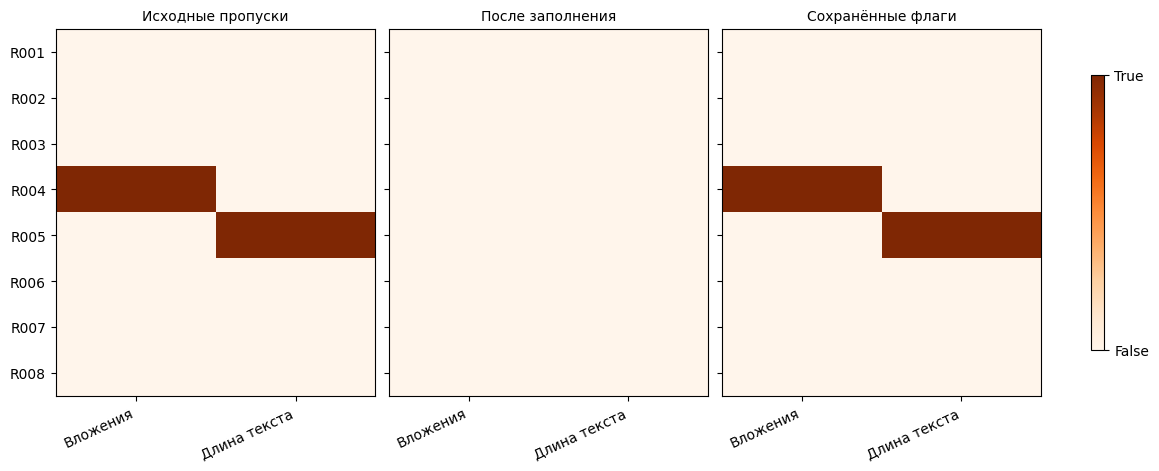

In [22]:
missing_figure, missing_axes = plt.subplots(1, 3, figsize=(11.5, 4.6), sharey=True)
missing_panels = [
    ('Исходные пропуски', training_numbers.isna().to_numpy()),
    ('После заполнения', filled_training_numbers.isna().to_numpy()),
    ('Сохранённые флаги', training_missing_flags.to_numpy()),
]
for axis, (title, values) in zip(missing_axes, missing_panels):
    image = axis.imshow(values, aspect='auto', cmap='Oranges', vmin=0, vmax=1)
    axis.set_title(title, fontsize=10)
    axis.set_xticks([0, 1], ['Вложения', 'Длина текста'], rotation=25, ha='right')
    axis.set_yticks(range(len(training_numbers)), training_numbers.index)

colorbar = missing_figure.colorbar(image, ax=missing_axes, ticks=[0, 1], shrink=0.75)
colorbar.ax.set_yticklabels(['False', 'True'])
plt.show()

**Разбор подготовки и обхода областей.**

- `plt.subplots(1, 3, ...)` создаёт три области в одной строке. `figsize` задаёт общий размер, `sharey=True` согласует вертикальные подписи обращений.
- В списке `missing_panels` каждый кортеж содержит заголовок и таблицу логических значений. `.isna()` отмечает пропуски, `.to_numpy()` передаёт значения рисунку без текстовых подписей Pandas.
- `zip(missing_axes, missing_panels)` соединяет области и описания попарно в их порядке. Запись `for axis, (title, values) in ...:` распаковывает пару, а затем второй её элемент — на заголовок и данные.

**Разбор изображения.**

- `.imshow(values, ...)` показывает небольшую таблицу как цветные клетки. `aspect='auto'` подстраивает пропорции под область, `cmap='Oranges'` выбирает палитру, `vmin=0`, `vmax=1` фиксируют одинаковое соответствие цветов значениям во всех областях.
- `.set_title(...)` задаёт заголовок. `.set_xticks([0, 1], [...], ...)` ставит подписи двух полей; `rotation=25` поворачивает текст, `ha='right'` выравнивает его по правому краю точки привязки.
- `.set_yticks(range(len(training_numbers)), training_numbers.index)` задаёт позиции всех строк и их идентификаторы. `len(...)` считает строки, `range(...)` выдаёт позиции от нуля.
- `.colorbar(image, ax=missing_axes, ticks=[0, 1], shrink=0.75)` добавляет общую шкалу цвета. `ax` указывает связанные области, `ticks` фиксирует два деления, `shrink` уменьшает высоту шкалы.
- `.ax` выбирает область самой цветовой шкалы. `.set_yticklabels(...)` назначает подписи False и True. `plt.show()` показывает готовый рисунок.

У R004 отмечено отсутствие вложений, у R005 — отсутствие длины сообщения. Эти сведения сохранились справа, хотя в числовой заполненной таблице уже нет пустых клеток.

### 6.3. Масштаб новых значений относительно учебных

Следующий рисунок показывает одно и то же поле до и после изменения масштаба. Цвет разделяет учебные и новые объекты. Значения сравниваются в рамках каждой области с её собственной подписью шкалы.

Новая большая величина может остаться большой и в преобразованном представлении. Автоматическое обрезание или повторная настройка по новым данным скрыли бы это различие, поэтому в этом примере они не включены.

Последний кодовый блок показывает количество вложений после выбранного заполнения и после применения учебного масштаба. Пунктир отмечает верхнюю границу учебного представления. Нулевое значение N002 здесь технически заполнено; информация о его отсутствии сохранена отдельным флагом.

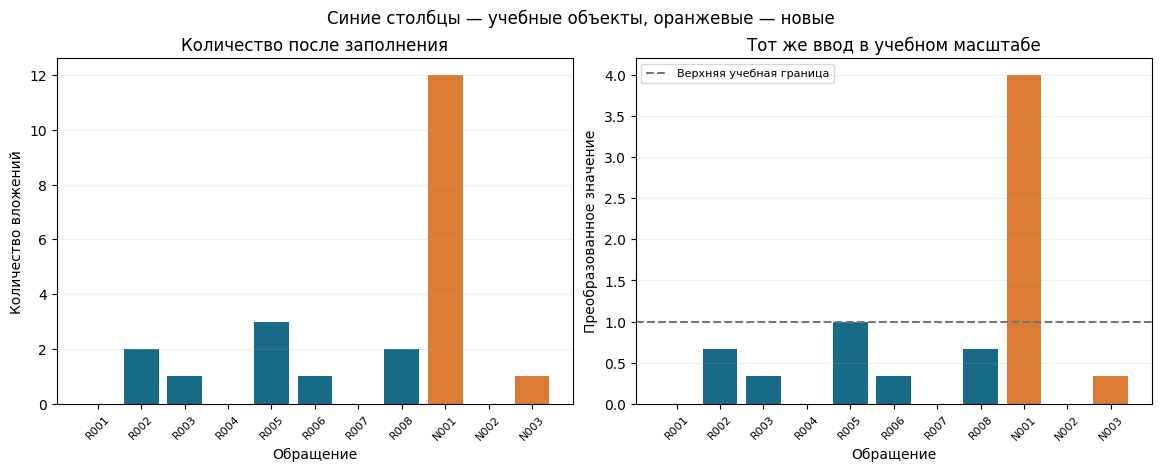

In [23]:
attachment_values = pd.concat([
    filled_training_numbers['attachment_count'], filled_new_numbers['attachment_count'],
])
attachment_scaled = pd.concat([
    scaled_training_numbers['attachment_count'], scaled_new_numbers['attachment_count'],
])
bar_colors = ['#176B87'] * len(training_numbers) + ['#DC7B34'] * len(new_numbers)

scale_figure, scale_axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
scale_axes[0].bar(attachment_values.index, attachment_values.to_numpy(), color=bar_colors)
scale_axes[1].bar(attachment_scaled.index, attachment_scaled.to_numpy(), color=bar_colors)
scale_axes[0].set(title='Количество после заполнения', ylabel='Количество вложений')
scale_axes[1].set(title='Тот же ввод в учебном масштабе', ylabel='Преобразованное значение')
scale_axes[1].axhline(1, color='#777777', linestyle='--', label='Верхняя учебная граница')
scale_axes[1].legend(loc='upper left', fontsize=8)
for axis in scale_axes:
    axis.tick_params(axis='x', labelrotation=45, labelsize=8)
    axis.grid(axis='y', alpha=0.2)
    axis.set_xlabel('Обращение')
scale_figure.suptitle('Синие столбцы — учебные объекты, оранжевые — новые')
plt.show()

**Разбор данных для рисунка.**

- `pd.concat([...])` соединяет две Series последовательно по строкам; направление по умолчанию — `axis=0`. Идентификаторы учебных и новых обращений различаются и сохраняются в индексе.
- Первый набор содержит заполненные исходные количества, второй — результаты того же поля после масштабирования. Для обеих областей сохранён одинаковый порядок объектов.
- `['#176B87'] * len(training_numbers)` повторяет список одного цвета по числу учебных строк. Оператор `*` для списка означает повторение. Оператор `+` соединяет его с таким же списком оранжевого цвета для новых строк.

**Разбор столбцов и подписей.**

- `plt.subplots(1, 2, ...)` создаёт две области. Выбор `[0]`, `[1]` обращается к левой и правой. `.bar(...)` получает подписи из `.index` и высоты из `.to_numpy()`; список `color` задаёт цвет каждого столбца.
- `.set(...)` задаёт отдельные заголовки и подписи шкал. `.axhline(1, ...)` справа добавляет горизонтальную линию; `linestyle='--'` делает её штриховой, `label` задаёт текст легенды.
- `.legend(...)` показывает подпись линии. Цикл `for axis in scale_axes:` одинаково оформляет обе области. `.tick_params(...)` поворачивает и уменьшает подписи горизонтальной оси.
- `.grid(axis='y', alpha=0.2)` добавляет лёгкую сетку, `.set_xlabel(...)` подписывает обращения. `.suptitle(...)` назначает заголовок всему рисунку, `plt.show()` выводит его.

У N001 двенадцать вложений, и его преобразованное значение выше учебной границы. Эти результаты получены неизменным процессом: доступные поля, одинаковое выделение признаков, сохранённые правила обработки и фиксированная схема выходных столбцов.